# Connect to data

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

file_path = "https://www.nhc.noaa.gov/data/hurdat/hurdat2-1851-2025-092326.txt"

column_names = [
    'ID-Date', 'Time', 'RecordID', 'Status', 'Latitude', 'Longitude',
    'WindSpeed', 'Pressure', *[f'ExtraField{i}' for i in range(1, 14)]
]

df = pd.read_csv(
    file_path,
    header=None,
    names=column_names,
    engine='python',
    skipinitialspace=True,
    dtype='string',
)

df.head()

,ID-Date,Time,RecordID,Status,Latitude,Longitude,WindSpeed,Pressure,ExtraField1,ExtraField2,...,ExtraField4,ExtraField5,ExtraField6,ExtraField7,ExtraField8,ExtraField9,ExtraField10,ExtraField11,ExtraField12,ExtraField13
0,AL011851,UNNAMED,14,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
1,18510625,0000,<NA>,HU,28.0N,94.8W,80,-999,-999,-999,...,-999,-999,-999,-999,-999,-999,-999,-999,-999,-999
2,18510625,0600,<NA>,HU,28.0N,95.4W,80,-999,-999,-999,...,-999,-999,-999,-999,-999,-999,-999,-999,-999,-999
3,18510625,1200,<NA>,HU,28.0N,96.0W,80,-999,-999,-999,...,-999,-999,-999,-999,-999,-999,-999,-999,-999,-999
4,18510625,1800,<NA>,HU,28.1N,96.5W,80,-999,-999,-999,...,-999,-999,-999,-999,-999,-999,-999,-999,-999,-999


# Clean and filter data
We had to create a UNIQUEID for each storm given the layout of the Hurdat2 data set.

In [10]:
# Storm-header rows contain the storm ID; forward-fill it onto track rows.
# The pattern r'[A-Z]{2}\d{6}' matches a value consisting of exactly two uppercase letters followed by six digits, such as AL011851. fullmatch requires the entire value to match—not just part of it.
storm_header_mask = df['ID-Date'].str.fullmatch(r'[A-Z]{2}\d{6}', na=False)

# Identify storm header rows.
df['UNIQUE_ID'] = df['ID-Date'].where(storm_header_mask).ffill()

# Remove the header rows.
df = df.loc[~storm_header_mask].copy()

# Create year and month columns in the dataframe.
df['YEAR'] = pd.to_numeric(df['ID-Date'].str[:4], errors='coerce').astype('Int64')
df['MONTH'] = df['ID-Date'].str[4:6]

# Convert wind speeds to numbers, turning unreadable values into missing values. Negative speeds are replaced with missing values.
df['WindSpeed'] = pd.to_numeric(df['WindSpeed'], errors='coerce')
df['WindSpeed'] = df['WindSpeed'].mask(df['WindSpeed'] < 0)

df.head()

,ID-Date,Time,RecordID,Status,Latitude,Longitude,WindSpeed,Pressure,ExtraField1,ExtraField2,...,ExtraField7,ExtraField8,ExtraField9,ExtraField10,ExtraField11,ExtraField12,ExtraField13,UNIQUE_ID,YEAR,MONTH
1,18510625,0000,<NA>,HU,28.0N,94.8W,80,-999,-999,-999,...,-999,-999,-999,-999,-999,-999,-999,AL011851,1851,06
2,18510625,0600,<NA>,HU,28.0N,95.4W,80,-999,-999,-999,...,-999,-999,-999,-999,-999,-999,-999,AL011851,1851,06
3,18510625,1200,<NA>,HU,28.0N,96.0W,80,-999,-999,-999,...,-999,-999,-999,-999,-999,-999,-999,AL011851,1851,06
4,18510625,1800,<NA>,HU,28.1N,96.5W,80,-999,-999,-999,...,-999,-999,-999,-999,-999,-999,-999,AL011851,1851,06
5,18510625,2100,L,HU,28.2N,96.8W,80,-999,-999,-999,...,-999,-999,-999,-999,-999,-999,-999,AL011851,1851,06


# Questions:

1. How many hurricanes were there per year?
2. How many storms by category were there per year?

In [11]:
# Count each storm once in its season year if its maximum wind reached 64 knots.
storm_stats = df.groupby('UNIQUE_ID', as_index=False).agg(
    max_wind=('WindSpeed', 'max')
)
storm_stats['SEASON_YEAR'] = pd.to_numeric(
    storm_stats['UNIQUE_ID'].str[-4:], errors='coerce'
)

hurricanes_by_year = (
    storm_stats.loc[storm_stats['max_wind'] >= 74]
    .groupby('SEASON_YEAR')
    .size()
    .rename('HURRICANE_COUNT')
)
hurricanes_by_year

SEASON_YEAR
1851     3
1852     3
1853     3
1854     2
1855     3
        ..
2019     4
2020    11
2021     5
2022     8
2023     6
Name: HURRICANE_COUNT, Length: 170, dtype: int64

## Visualize the data

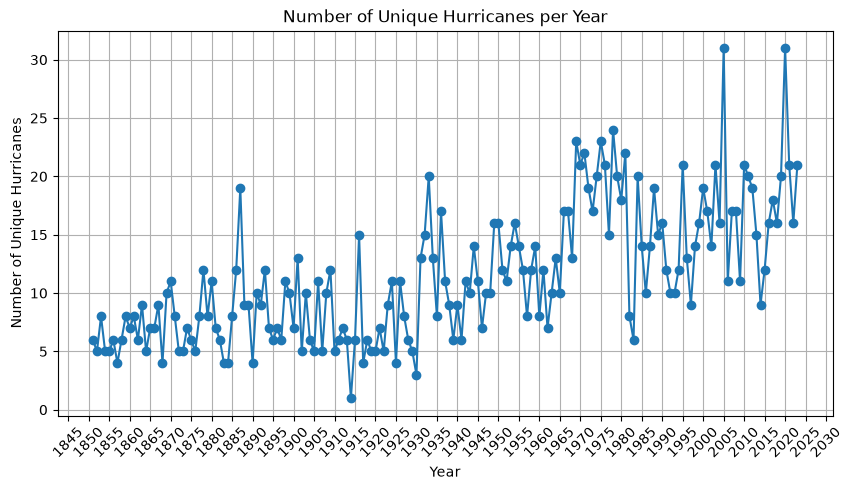

In [12]:
# Convert the YEAR column to numeric, coercing errors to NaN
df['YEAR'] = pd.to_numeric(df['YEAR'], errors='coerce')

# Drop rows where YEAR is NaN (invalid year data)
df_clean = df.dropna(subset=['YEAR'])

# Convert YEAR to integer using .loc to avoid the SettingWithCopyWarning
df_clean.loc[:,'YEAR'] = df_clean['YEAR'].astype(int)  # The [:, 'YEAR'] element instructs Pandas to select all rows in the 'YEAR' column.

# Now, group by the cleaned 'YEAR' and count unique hurricanes
hurricanes_by_year = df_clean.groupby('YEAR')['UNIQUE_ID'].nunique()

# Plot the result
plt.figure(figsize=(10, 5))
plt.plot(hurricanes_by_year.index, hurricanes_by_year.values, marker='o')

plt.xlabel('Year')
plt.ylabel('Number of Unique Hurricanes')
plt.title('Number of Unique Hurricanes per Year')

# Adjust the X-axis ticks for better visibility.
plt.gca().xaxis.set_major_locator(plt.MultipleLocator(5))
plt.xticks(rotation=45)

plt.grid(True)
plt.show()

Add an average line.

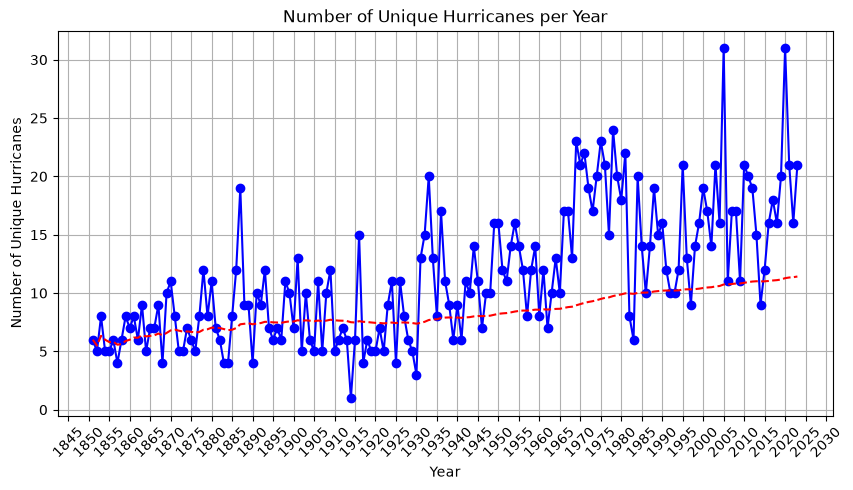

In [ ]:
# Convert the YEAR column to numeric, coercing errors to NaN
df['YEAR'] = pd.to_numeric(df['YEAR'], errors='coerce')

# Drop rows where YEAR is NaN (invalid year data)
df_clean = df.dropna(subset=['YEAR'])

# Convert YEAR to integer using .loc to avoid the SettingWithCopyWarning
df_clean.loc[:,'YEAR'] = df_clean['YEAR'].astype(int)  # The [:, 'YEAR'] element instructs Pandas to select all rows in the 'YEAR' column.

# Now, group by the cleaned 'YEAR' and count unique hurricanes
hurricanes_by_year = df_clean.groupby('YEAR')['UNIQUE_ID'].nunique()

# Calculate the cumulative average of hurricanes per year.
cumulative_avg_hurricanes = hurricanes_by_year.expanding().mean()

# Plot the result
plt.figure(figsize=(10, 5))
plt.plot(hurricanes_by_year.index, hurricanes_by_year.values, color='blue', marker='o')

# Plot the cumulative average.
plt.plot(cumulative_avg_hurricanes.index, cumulative_avg_hurricanes.values, color='red', linestyle='--', label='Cumulative Average')

plt.xlabel('Year')
plt.ylabel('Number of Unique Hurricanes')
plt.title('Number of Unique Hurricanes per Year')

# Adjust the X-axis ticks for better visibility.
plt.gca().xaxis.set_major_locator(plt.MultipleLocator(5))
plt.xticks(rotation=45)

plt.grid(True)
plt.show()

## Determine the category of storm.

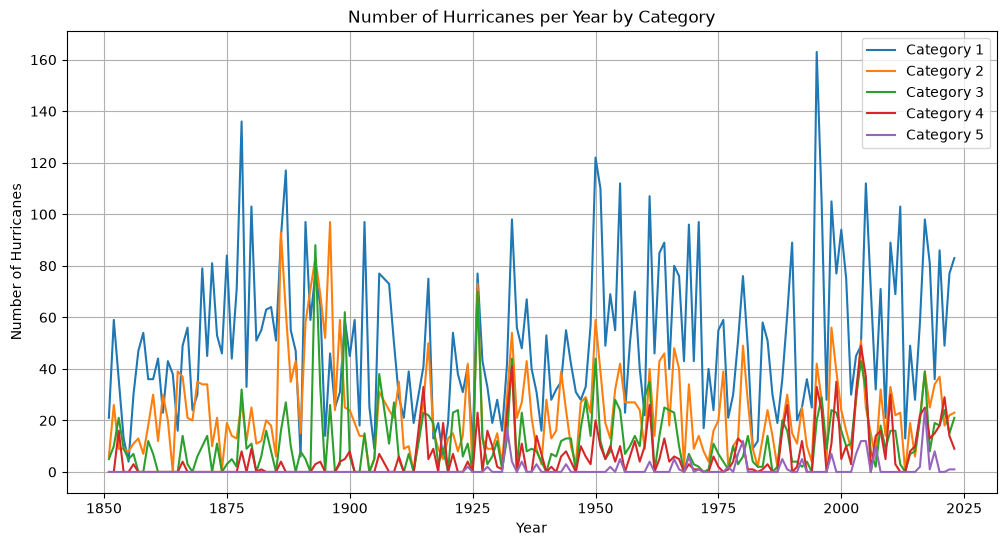

In [ ]:
# Add a new column with hurricane categories based on wind speeds
def categorize_wind_speed(knots):
    if pd.isna(knots) or knots < 64:
        return None
    elif knots <= 82:
        return "Category 1"
    elif knots <= 95:
        return "Category 2"
    elif knots <= 112:
        return "Category 3"
    elif knots <= 136:
        return "Category 4"
    else:
        return "Category 5"

df["CATEGORY"] = df["WindSpeed"].apply(categorize_wind_speed)

# We can also filter the data for only certain years of Hurricanes
# df = df[df['YEAR'] > 2000]

# Group the data by year and category, then count the number of hurricanes
# unstack(fill_value=0) will ensure any years with no Hurricanes will show as zero instead of NaN.
hurricanes_by_year_category = df.groupby(["YEAR", "CATEGORY"])["UNIQUE_ID"].count().unstack(fill_value=0) 

# Plot the line chart for each hurricane category
plt.figure(figsize=(12, 6))

for category in hurricanes_by_year_category.columns:
    plt.plot(hurricanes_by_year_category.index, hurricanes_by_year_category[category], label=category)

plt.xlabel("Year")
plt.ylabel("Number of Hurricanes")
plt.title("Number of Hurricanes per Year by Category")
plt.grid()
plt.legend()
plt.show()

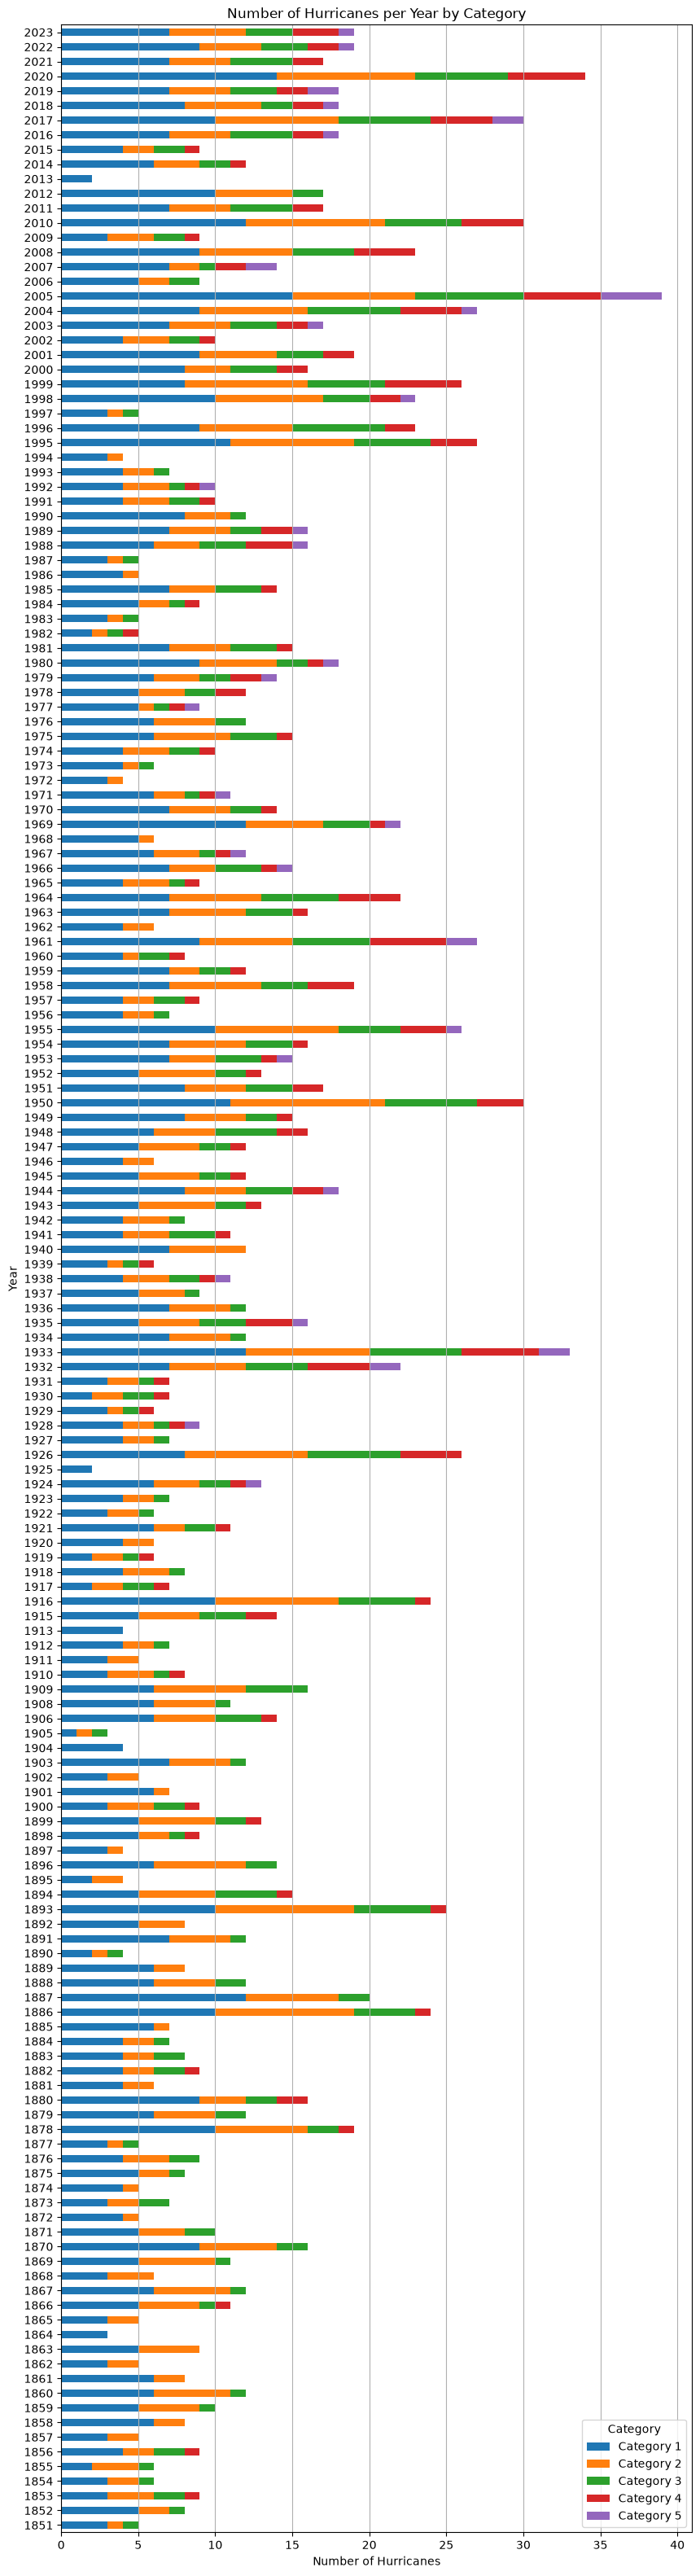

In [ ]:
# Stacked Bar

df["CATEGORY"] = df["WindSpeed"].apply(categorize_wind_speed)

# Group the data by 'YEAR' and 'CATEGORY', then count the number of unique hurricane IDs
# and unstack the categories for plotting
hurricanes_by_year_category = df.groupby(["YEAR", "CATEGORY"])["UNIQUE_ID"].nunique().unstack(fill_value=0)

# Plot the stacked horizontal bar chart for each hurricane category
hurricanes_by_year_category.plot(kind="barh", stacked=True, figsize=(10, 40))  # Adjusted figsize for better visibility in horizontal orientation

# Customize the plot
plt.ylabel("Year")  # Note the switch of x and y labels
plt.xlabel("Number of Hurricanes")
plt.title("Number of Hurricanes per Year by Category")
plt.grid(axis='x')  # Switched to grid along the x-axis
plt.legend(title="Category")

# Display the chart
plt.show()